# Open Interest Analysis - ETH + BTC

Deep dive into **where the option market is positioned**.

Open interest tells you **where money is committed**, not just what traded today. It's the map of where the market will defend or attack.

**Sections:**

1. Fetch live option chains
2. Total OI overview
3. OI by strike (walls)
4. OI by expiry (term structure)
5. OI by moneyness (OTM vs ATM vs ITM)
6. OI heatmap (strike × expiry)
7. Call wall vs put wall distance
8. Max pain (OI-based price magnet)
9. Strike concentration (how manipulated?)
10. OI dominance by side
11. Final verdict per coin

## Setup

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (13, 5)

DERIBIT = 'https://www.deribit.com/api/v2/public'
COINS = ['BTC', 'ETH']
print('ready')

ready


## 1. Fetch live option chains

In [2]:
def fetch_chain(currency):
    r = requests.get(f'{DERIBIT}/get_book_summary_by_currency',
                     params={'currency': currency, 'kind': 'option'}, timeout=20)
    r.raise_for_status()
    return r.json()['result']


def parse_name(name):
    parts = name.split('-')
    if len(parts) != 4: return None
    try:
        _, exp, strike, kind = parts
        dt = datetime.strptime(exp, '%d%b%y').replace(tzinfo=timezone.utc, hour=8)
        return int(dt.timestamp() * 1000), float(strike), kind
    except (ValueError, IndexError):
        return None


frames = []
for cur in COINS:
    raw = fetch_chain(cur)
    now_ms = int(time.time() * 1000)
    rows = []
    for r in raw:
        p = parse_name(r['instrument_name'])
        if p is None: continue
        rows.append({
            'coin': cur, 'expiry': p[0], 'strike': p[1], 'kind': p[2],
            'ts': now_ms,
            'mark': r.get('mark_price'),
            'iv': r.get('mark_iv'),
            'oi': r.get('open_interest') or 0,
            'volume': r.get('volume') or 0,
            'underlying_price': r.get('underlying_price'),
        })
    frames.append(pd.DataFrame(rows))
    print(f'{cur}: {len(rows)} contracts')
    time.sleep(0.3)

df = pd.concat(frames, ignore_index=True)
df['days'] = (df['expiry'] - df['ts']) / 86_400_000
df['iv_dec'] = df['iv'] / 100.0

spots = {}
for cur in COINS:
    s = df[df.coin == cur]
    v = s[s.underlying_price.notna()]
    spots[cur] = float(v.underlying_price.iloc[0]) if len(v) else float(s.strike.median())

print(f'\ntotal contracts: {len(df)}')
for k, v in spots.items(): print(f'  {k} spot: {v:,.2f}')

BTC: 876 contracts
ETH: 734 contracts

total contracts: 1610
  BTC spot: 80,667.83
  ETH spot: 2,332.29


## 2. Total OI overview

**What this tells you:** the absolute size of the market. Coins with tiny OI can't be trusted for signal.

In [3]:
overview = []
for cur in COINS:
    s = df[df.coin == cur]
    call_oi = s[s.kind=='C'].oi.sum()
    put_oi  = s[s.kind=='P'].oi.sum()
    total   = call_oi + put_oi
    notional = (s.mark.fillna(0) * s.oi).sum()
    overview.append({
        'coin': cur,
        'contracts': len(s),
        'call_oi': int(call_oi),
        'put_oi':  int(put_oi),
        'total_oi': int(total),
        'pcr': put_oi / max(call_oi, 1),
        'notional_usd_M': notional / 1e6,
    })

ov = pd.DataFrame(overview)
print(ov.to_string(index=False))

coin  contracts  call_oi  put_oi  total_oi      pcr  notional_usd_M
 BTC        876   242200  145005    387206 0.598700        0.011203
 ETH        734  1004625  498755   1503380 0.496459        0.068637


## 3. OI by strike - the walls

**What this tells you:** where price will get blocked (call wall) or supported (put wall). These are the actual price levels where institutions defend positions.

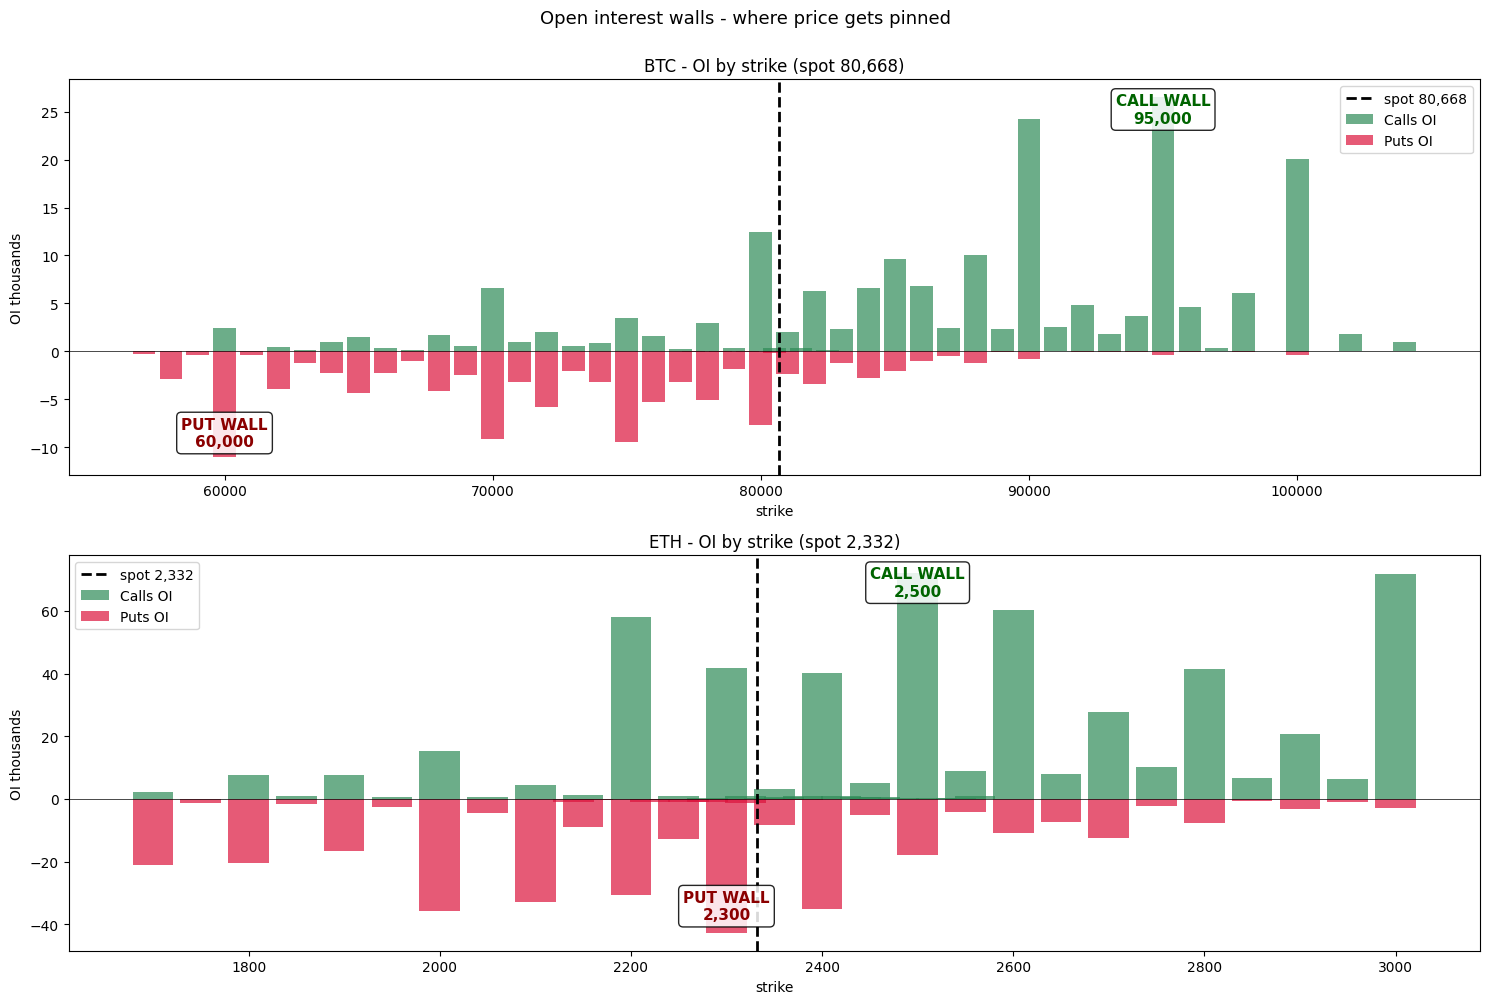

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))
walls = {}

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur]
    spot = spots[cur]
    s_near = s[(s.strike > spot * 0.7) & (s.strike < spot * 1.3)]
    pivot = s_near.pivot_table(index='strike', columns='kind',
                                values='oi', aggfunc='sum').fillna(0)

    if len(pivot) == 0:
        ax.axis('off'); continue

    x = pivot.index
    width = (x[1] - x[0]) * 0.85 if len(x) > 1 else 100
    ax.bar(x, pivot['C'] / 1e3, width, color='seagreen', alpha=0.7, label='Calls OI')
    ax.bar(x, -pivot['P'] / 1e3, width, color='crimson', alpha=0.7, label='Puts OI')
    ax.axvline(spot, color='black', lw=2, ls='--', label=f'spot {spot:,.0f}')
    ax.axhline(0, color='black', lw=0.5)

    call_wall = pivot['C'].idxmax()
    put_wall  = pivot['P'].idxmax()
    walls[cur] = {'call': float(call_wall), 'put': float(put_wall),
                  'call_oi': float(pivot['C'].max()), 'put_oi': float(pivot['P'].max())}

    ax.text(call_wall, pivot['C'].max() / 1e3 * 0.9, f'CALL WALL\n{call_wall:,.0f}',
            ha='center', color='darkgreen', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))
    ax.text(put_wall, -pivot['P'].max() / 1e3 * 0.9, f'PUT WALL\n{put_wall:,.0f}',
            ha='center', color='darkred', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

    ax.set_title(f'{cur} - OI by strike (spot {spot:,.0f})', fontsize=12)
    ax.set_xlabel('strike'); ax.set_ylabel('OI thousands')
    ax.legend()

plt.suptitle('Open interest walls - where price gets pinned', fontsize=13, y=1.0)
plt.tight_layout(); plt.show()

## 4. OI by expiry - term structure of positioning

**What this tells you:** is the market making bets 1 week out or 3 months out? Short-dated OI = tactical traders. Long-dated OI = strategic institutions.

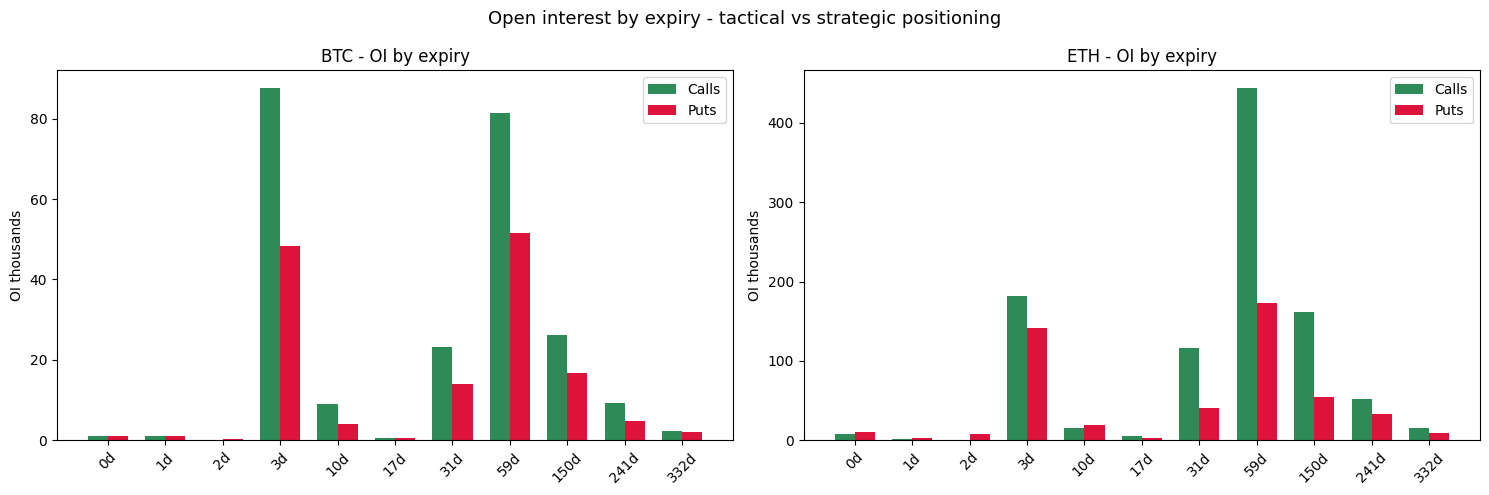

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur]
    s = s[(s.days > 0) & (s.days < 400)]
    if len(s) == 0: continue
    by_exp = s.groupby(['expiry', 'kind']).oi.sum().unstack('kind').fillna(0)
    by_exp['days'] = (by_exp.index - int(time.time() * 1000)) / 86_400_000
    by_exp = by_exp.sort_values('days').head(12)

    x = np.arange(len(by_exp))
    w = 0.35
    ax.bar(x - w/2, by_exp['C'] / 1e3, w, label='Calls', color='seagreen')
    ax.bar(x + w/2, by_exp['P'] / 1e3, w, label='Puts', color='crimson')
    ax.set_xticks(x)
    ax.set_xticklabels([f'{int(d)}d' for d in by_exp.days], rotation=45)
    ax.set_title(f'{cur} - OI by expiry')
    ax.set_ylabel('OI thousands'); ax.legend()

plt.suptitle('Open interest by expiry - tactical vs strategic positioning', fontsize=13)
plt.tight_layout(); plt.show()

## 5. OI by moneyness

**What this tells you:** is protection at real strikes (near spot) or at lottery-ticket strikes (deep OTM)?

- ATM = real directional bets
- OTM = meaningful hedging
- Deep OTM = lottery tickets / cheap insurance

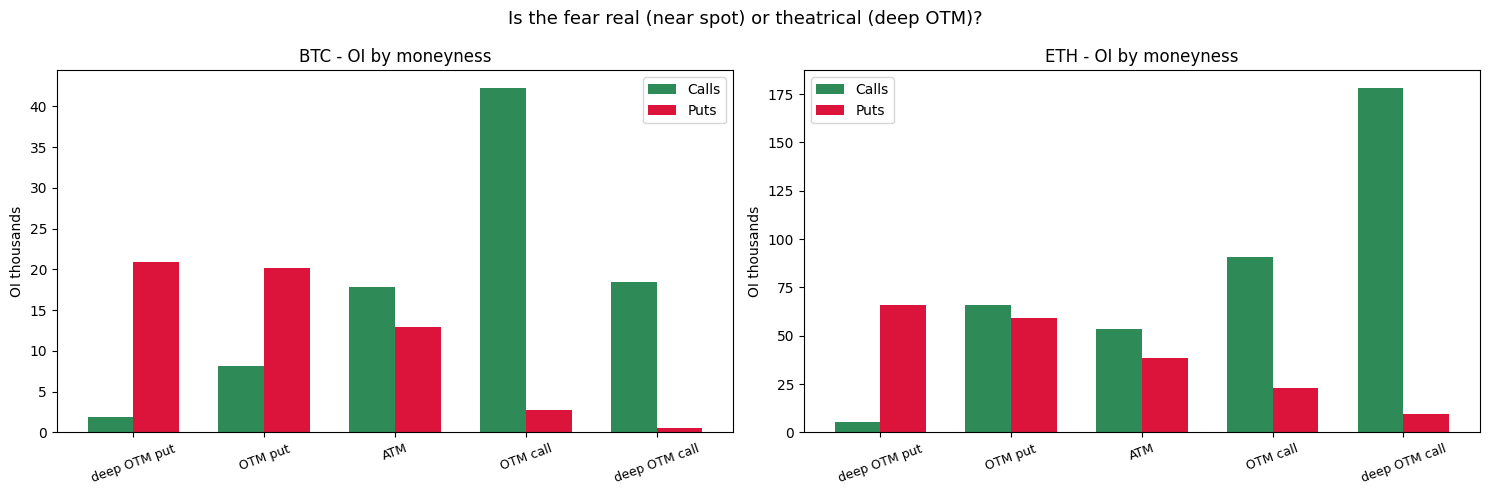

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    s = df[(df.coin == cur) & (df.days.between(7, 90))].copy()
    if len(s) == 0: continue
    spot = spots[cur]
    s['moneyness'] = (s.strike - spot) / spot * 100
    s = s[s.moneyness.between(-40, 40)]

    def bucket(m):
        if m < -20: return 'deep OTM put'
        if m < -5:  return 'OTM put'
        if m <= 5:  return 'ATM'
        if m <= 20: return 'OTM call'
        return 'deep OTM call'

    s['bucket'] = s.moneyness.map(bucket)
    b = s.groupby(['bucket', 'kind']).oi.sum().unstack('kind').fillna(0)
    order = ['deep OTM put', 'OTM put', 'ATM', 'OTM call', 'deep OTM call']
    b = b.reindex(order).fillna(0)

    x = np.arange(len(b))
    w = 0.35
    ax.bar(x - w/2, b.get('C', 0) / 1e3, w, label='Calls', color='seagreen')
    ax.bar(x + w/2, b.get('P', 0) / 1e3, w, label='Puts', color='crimson')
    ax.set_xticks(x)
    ax.set_xticklabels(b.index, rotation=20, fontsize=9)
    ax.set_title(f'{cur} - OI by moneyness')
    ax.set_ylabel('OI thousands'); ax.legend()

plt.suptitle('Is the fear real (near spot) or theatrical (deep OTM)?', fontsize=13)
plt.tight_layout(); plt.show()

## 6. OI heatmap - strike × expiry

**What this tells you:** every combination at once. Dark red = huge OI = pin points. Dark blue = low OI = thin liquidity.

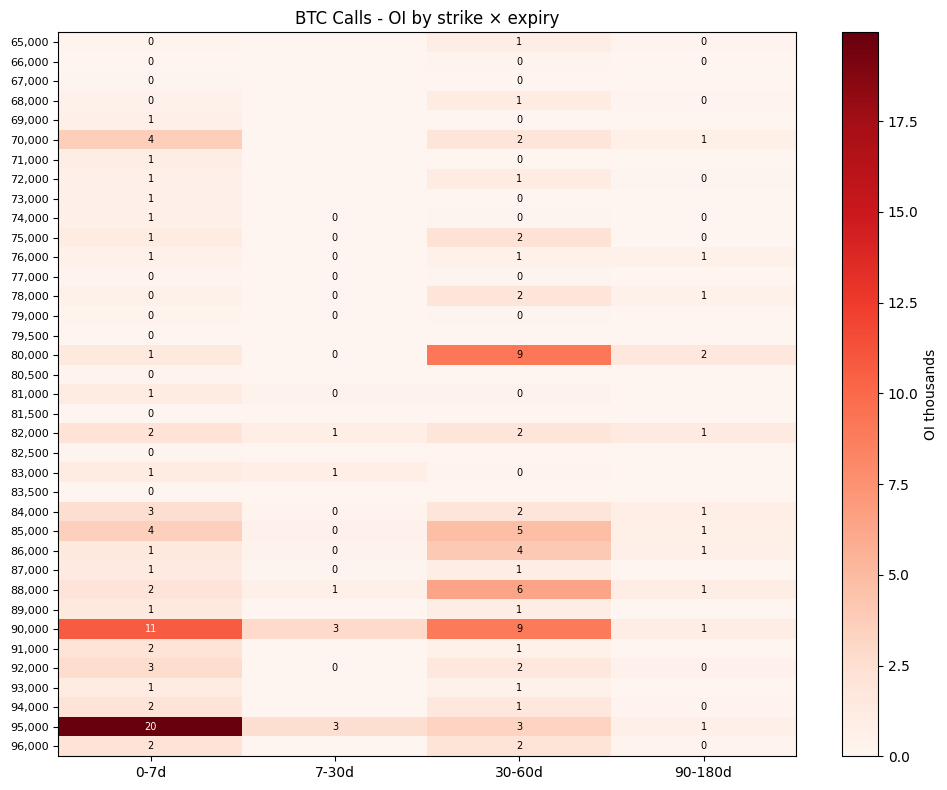

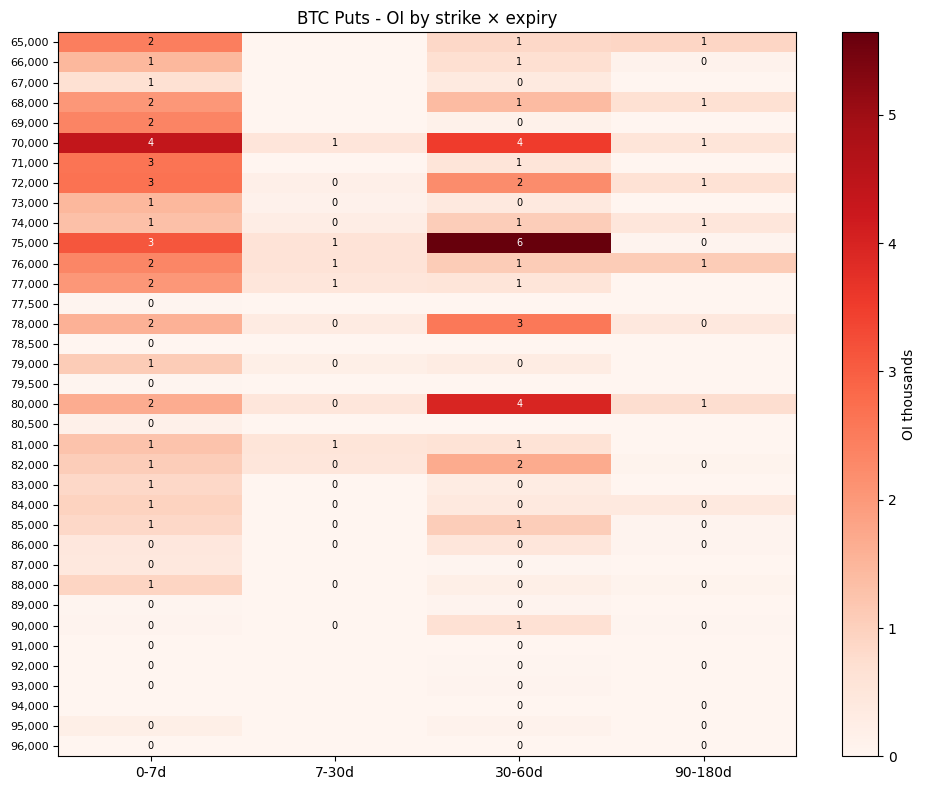

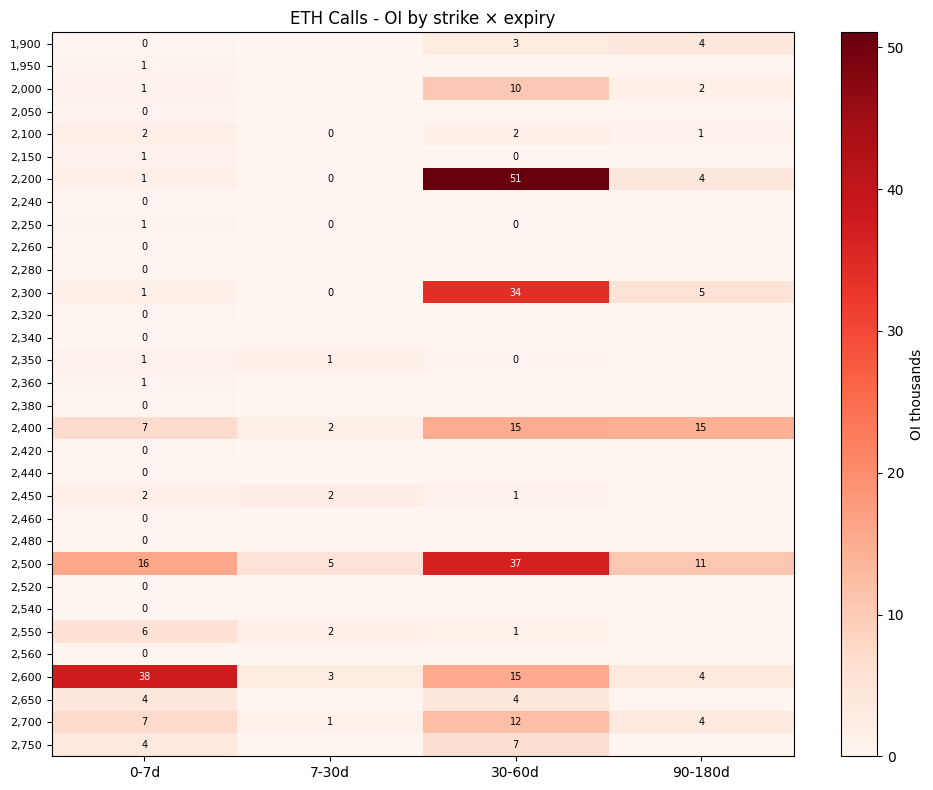

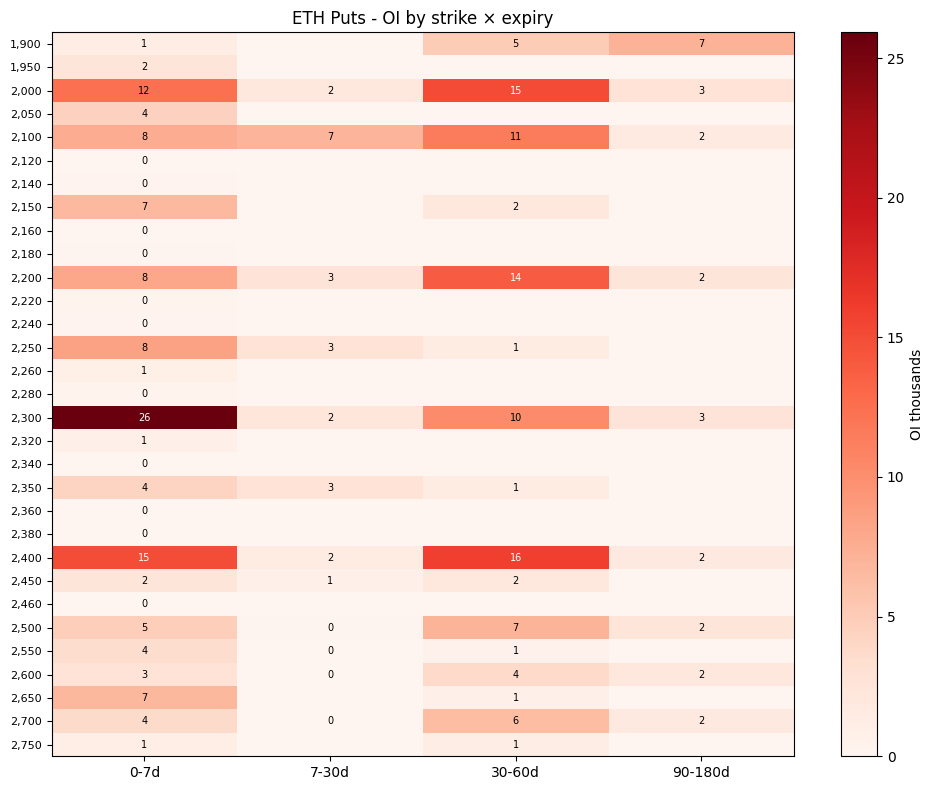

In [7]:
for cur in COINS:
    s = df[(df.coin == cur) & (df.days.between(1, 180)) & (df.oi > 0)].copy()
    spot = spots[cur]
    s = s[(s.strike > spot * 0.8) & (s.strike < spot * 1.2)]
    if len(s) == 0: continue

    s['exp_bucket'] = pd.cut(s.days,
                             bins=[0, 7, 30, 60, 90, 180],
                             labels=['0-7d', '7-30d', '30-60d', '60-90d', '90-180d'])

    for kind in ['C', 'P']:
        sk = s[s.kind == kind]
        if len(sk) == 0: continue
        pivot = sk.pivot_table(index='strike', columns='exp_bucket',
                               values='oi', aggfunc='sum', observed=True).fillna(0)

        fig, ax = plt.subplots(figsize=(10, 8))
        im = ax.imshow(pivot.values / 1e3, cmap='Reds', aspect='auto')
        ax.set_xticks(range(len(pivot.columns)))
        ax.set_xticklabels(pivot.columns)
        ax.set_yticks(range(len(pivot.index)))
        ax.set_yticklabels([f'{s:,.0f}' for s in pivot.index], fontsize=8)
        for i in range(pivot.shape[0]):
            for j in range(pivot.shape[1]):
                v = pivot.iloc[i, j]
                if v > 0:
                    ax.text(j, i, f'{v/1e3:.0f}',
                            ha='center', va='center', fontsize=7,
                            color='white' if v > pivot.values.max() * 0.5 else 'black')
        plt.colorbar(im, ax=ax, label='OI thousands')
        label = 'Calls' if kind == 'C' else 'Puts'
        ax.set_title(f'{cur} {label} - OI by strike × expiry')
        plt.tight_layout(); plt.show()

## 7. Call wall vs put wall distance

**What this tells you:** how far the walls are from spot. If a wall is very close, expect pinning soon. If far, price has room to move.

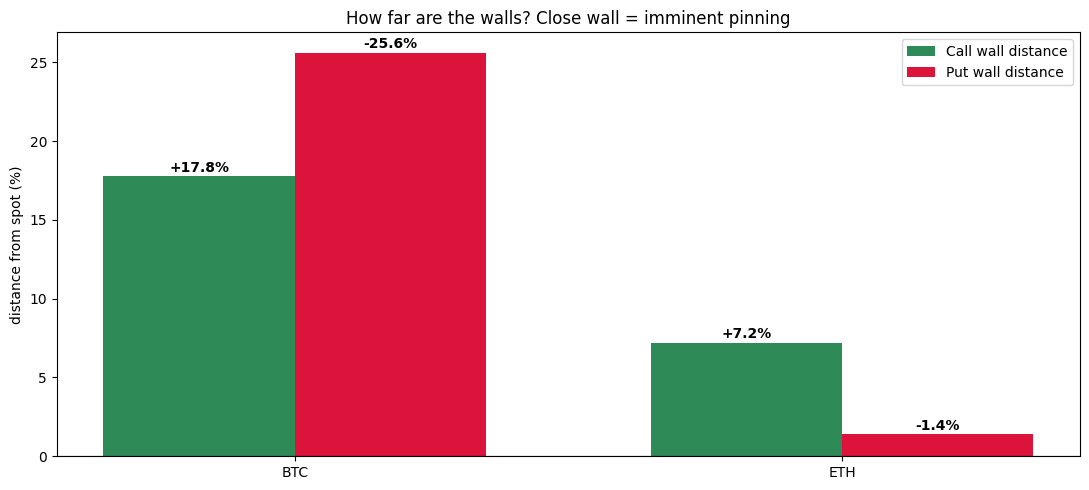

Wall distance summary:
  BTC: call wall +17.8%  put wall -25.6%
  ETH: call wall +7.2%  put wall -1.4%


In [8]:
fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(COINS))
w = 0.35
call_dists = []
put_dists = []

for cur in COINS:
    w_data = walls.get(cur, {})
    spot = spots[cur]
    call_dists.append((w_data.get('call', spot) - spot) / spot * 100)
    put_dists.append((spot - w_data.get('put', spot)) / spot * 100)

bars1 = ax.bar(x - w/2, call_dists, w, color='seagreen', label='Call wall distance')
bars2 = ax.bar(x + w/2, put_dists,  w, color='crimson', label='Put wall distance')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(COINS)
ax.set_ylabel('distance from spot (%)')
ax.set_title('How far are the walls? Close wall = imminent pinning')
ax.legend()

for b, v in zip(bars1, call_dists):
    ax.text(b.get_x() + b.get_width()/2, v + 0.3, f'{v:+.1f}%',
            ha='center', fontweight='bold')
for b, v in zip(bars2, put_dists):
    ax.text(b.get_x() + b.get_width()/2, v + 0.3, f'-{v:.1f}%',
            ha='center', fontweight='bold')

plt.tight_layout(); plt.show()

print('Wall distance summary:')
for i, cur in enumerate(COINS):
    print(f'  {cur}: call wall +{call_dists[i]:.1f}%  put wall -{put_dists[i]:.1f}%')

## 8. Max pain - where OI magnetizes price

**What this tells you:** the strike where option buyers lose the most. Price tends to drift toward this strike as expiry approaches.

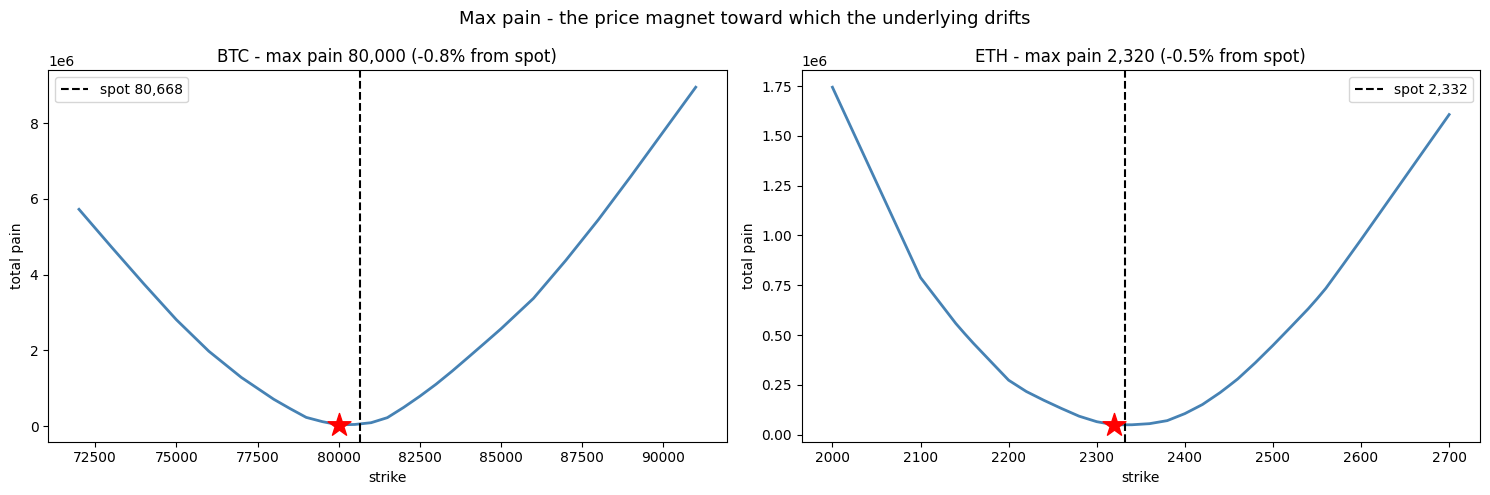

Max pain summary:
  BTC: max pain 80,000  (-0.8% -> drift DOWN)
  ETH: max pain 2,320  (-0.5% -> drift DOWN)


In [9]:
def max_pain(currency):
    s = df[df.coin == currency]
    sub = s[s.expiry == s.expiry.min()]
    if len(sub) == 0: return None, None
    strikes = sorted(sub.strike.unique())
    pains = {}
    for K in strikes:
        pain = 0.0
        for _, r in sub.iterrows():
            oi = r.oi or 0
            if r.kind == 'C': pain += oi * max(0.0, K - r.strike)
            else:            pain += oi * max(0.0, r.strike - K)
        pains[K] = pain
    return pains, min(pains, key=pains.get)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
mp_data = {}

for ax, cur in zip(axes, COINS):
    pains, mp = max_pain(cur)
    if pains is None:
        ax.axis('off'); continue
    mp_data[cur] = mp

    strikes = list(pains.keys())
    values = list(pains.values())
    ax.plot(strikes, values, lw=2, color='steelblue')
    ax.scatter([mp], [min(values)], color='red', s=300, marker='*', zorder=5)
    ax.axvline(spots[cur], color='black', ls='--', lw=1.5,
               label=f'spot {spots[cur]:,.0f}')
    dist = (mp - spots[cur]) / spots[cur] * 100
    ax.set_title(f'{cur} - max pain {mp:,.0f} ({dist:+.1f}% from spot)')
    ax.set_xlabel('strike'); ax.set_ylabel('total pain')
    ax.legend()

plt.suptitle('Max pain - the price magnet toward which the underlying drifts', fontsize=13)
plt.tight_layout(); plt.show()

print('Max pain summary:')
for cur, mp in mp_data.items():
    dist = (mp - spots[cur]) / spots[cur] * 100
    direction = 'UP' if dist > 0 else 'DOWN'
    print(f'  {cur}: max pain {mp:,.0f}  ({dist:+.1f}% -> drift {direction})')

## 9. Strike concentration

**What this tells you:** if 5 strikes hold 60%+ of OI, the market is controlled by few players → manipulation risk high. If OI is spread evenly, it's a real market.

coin  total_strikes  top1_pct  top5_pct  top10_pct
 BTC             90       6.9      27.9       43.2
 ETH             85       6.5      29.0       48.2


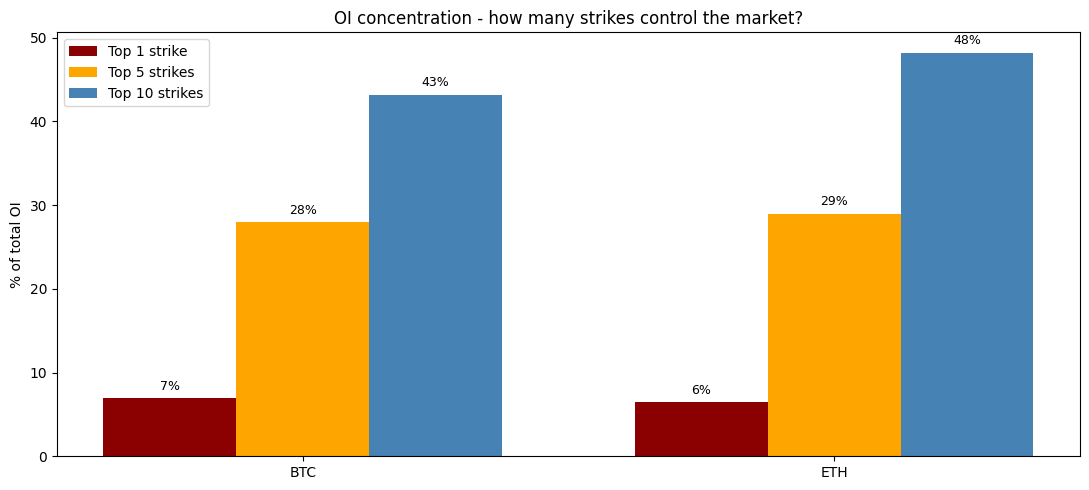

In [10]:
conc_data = []
for cur in COINS:
    s = df[df.coin == cur]
    oi_by_strike = s.groupby('strike').oi.sum().sort_values(ascending=False)
    total = oi_by_strike.sum()
    if total == 0: continue
    top1 = oi_by_strike.head(1).sum() / total * 100
    top5 = oi_by_strike.head(5).sum() / total * 100
    top10 = oi_by_strike.head(10).sum() / total * 100
    conc_data.append({
        'coin': cur,
        'total_strikes': len(oi_by_strike),
        'top1_pct': top1,
        'top5_pct': top5,
        'top10_pct': top10,
    })

conc = pd.DataFrame(conc_data)
print(conc.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(conc))
w = 0.25
ax.bar(x - w, conc.top1_pct,  w, label='Top 1 strike', color='darkred')
ax.bar(x,     conc.top5_pct,  w, label='Top 5 strikes', color='orange')
ax.bar(x + w, conc.top10_pct, w, label='Top 10 strikes', color='steelblue')
ax.set_xticks(x); ax.set_xticklabels(conc.coin)
ax.set_ylabel('% of total OI')
ax.set_title('OI concentration - how many strikes control the market?')
ax.legend()
for bars, vals in [(ax.patches[:len(conc)], conc.top1_pct),
                   (ax.patches[len(conc):2*len(conc)], conc.top5_pct),
                   (ax.patches[2*len(conc):], conc.top10_pct)]:
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 1, f'{v:.0f}%',
                ha='center', fontsize=9)
plt.tight_layout(); plt.show()

## 10. OI dominance by side

**What this tells you:** how lopsided the positioning is. More calls = bearish contrarian. More puts = bullish contrarian.

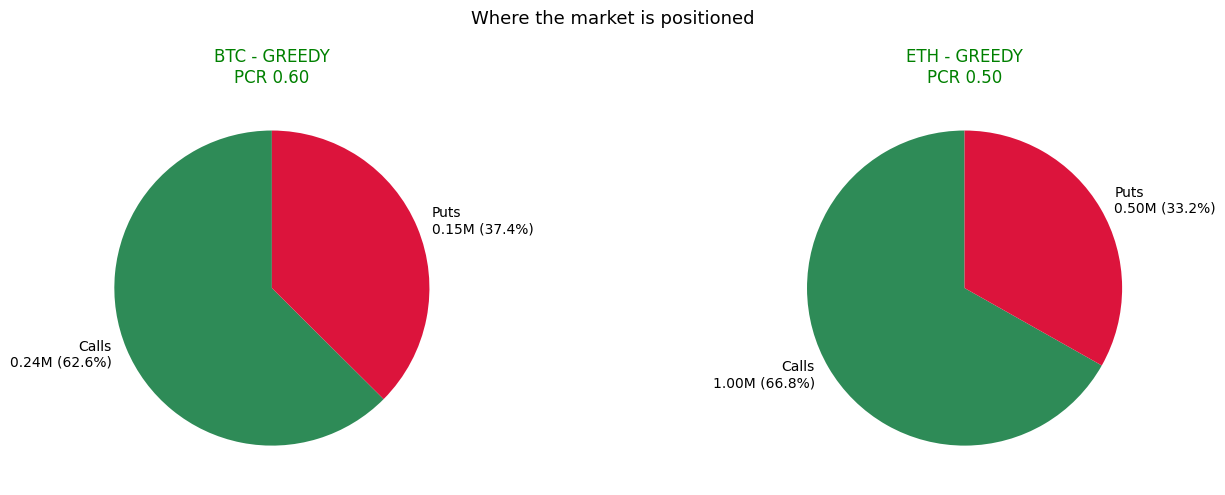

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur]
    calls = s[s.kind=='C'].oi.sum()
    puts = s[s.kind=='P'].oi.sum()
    total = calls + puts
    pct_c = calls / total * 100
    pct_p = puts / total * 100

    ax.pie([calls, puts], labels=[f'Calls\n{calls/1e6:.2f}M ({pct_c:.1f}%)',
                                    f'Puts\n{puts/1e6:.2f}M ({pct_p:.1f}%)'],
           colors=['seagreen', 'crimson'],
           autopct='', startangle=90)
    pcr = puts / max(calls, 1)
    if pcr > 1.15: label = 'FEARFUL' ; color = 'red'
    elif pcr < 0.85: label = 'GREEDY' ; color = 'green'
    else: label = 'BALANCED' ; color = 'black'
    ax.set_title(f'{cur} - {label}\nPCR {pcr:.2f}', color=color, fontsize=12)

plt.suptitle('Where the market is positioned', fontsize=13)
plt.tight_layout(); plt.show()

## 11. FINAL VERDICT per coin

In [12]:
print('=' * 72)
print('OI ANALYSIS VERDICT')
print('=' * 72)

for cur in COINS:
    s = df[df.coin == cur]
    spot = spots[cur]
    call_oi = s[s.kind=='C'].oi.sum()
    put_oi  = s[s.kind=='P'].oi.sum()
    pcr = put_oi / max(call_oi, 1)
    w = walls.get(cur, {})
    mp = mp_data.get(cur, spot)

    call_dist = (w.get('call', spot) - spot) / spot * 100
    put_dist  = (spot - w.get('put', spot)) / spot * 100
    mp_dist   = (mp - spot) / spot * 100

    print(f'\n{cur}  (spot {spot:,.0f})')
    print(f'  Total OI       : {call_oi + put_oi:,.0f} contracts')
    print(f'  Calls / Puts   : {call_oi:,.0f} / {put_oi:,.0f}')
    print(f'  PCR            : {pcr:.2f}')
    print(f'  Call wall      : {w.get("call", 0):,.0f}  ({call_dist:+.1f}%)  resistance')
    print(f'  Put wall       : {w.get("put", 0):,.0f}  (-{put_dist:.1f}%)  support')
    print(f'  Max pain       : {mp:,.0f}  ({mp_dist:+.1f}%)')

    # verdict logic
    if pcr > 1.15 and mp_dist > 1:
        verdict = 'BUY CALLS - fearful market + max pain above spot'
    elif pcr < 0.85 and mp_dist < -1:
        verdict = 'BUY PUTS - greedy market + max pain below spot'
    elif pcr > 1.15:
        verdict = 'mild CALL bias - fear present but no max pain pull'
    elif pcr < 0.85:
        verdict = 'mild PUT bias - greed present but no max pain pull'
    else:
        verdict = 'NEUTRAL - PCR balanced, wait for clear signal'
    print(f'  VERDICT        : {verdict}')

OI ANALYSIS VERDICT

BTC  (spot 80,668)
  Total OI       : 387,207 contracts
  Calls / Puts   : 242,201 / 145,006
  PCR            : 0.60
  Call wall      : 95,000  (+17.8%)  resistance
  Put wall       : 60,000  (-25.6%)  support
  Max pain       : 80,000  (-0.8%)
  VERDICT        : mild PUT bias - greed present but no max pain pull

ETH  (spot 2,332)
  Total OI       : 1,503,380 contracts
  Calls / Puts   : 1,004,625 / 498,755
  PCR            : 0.50
  Call wall      : 2,500  (+7.2%)  resistance
  Put wall       : 2,300  (-1.4%)  support
  Max pain       : 2,320  (-0.5%)
  VERDICT        : mild PUT bias - greed present but no max pain pull


## Notes

- All OI data is **live from Deribit**, no storage
- **Call wall** = highest call OI strike = resistance
- **Put wall** = highest put OI strike = support
- **Max pain** = strike where option buyers lose most = price magnet
- **High concentration** (top 5 > 60%) = market manipulated by few players
- **Deep OTM concentration** = theatrical fear, not real
- Combine with PCR notebook for direction, timing notebook for entry

OI vs Price: is OI confirming the move?


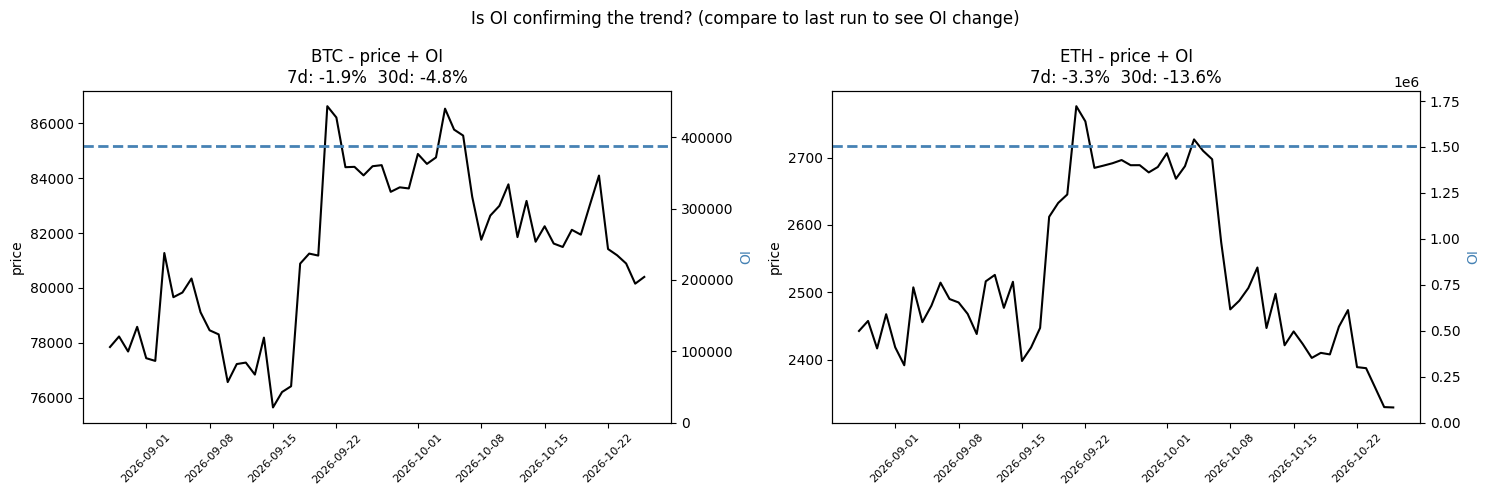


Trend confirmation check:
  If OI rose and price rose -> healthy uptrend
  If OI rose and price fell -> healthy downtrend
  If OI fell and price rose -> short squeeze (weak)
  If OI fell and price fell -> long liquidation (weak)


In [13]:
# Does rising OI confirm the price trend?
# Bullish confirmation: price up + OI up = new money driving the rally
# Weak rally: price up + OI down = short squeeze (no new money)
# Bearish confirmation: price down + OI up = new shorts
# Weak dump: price down + OI down = long liquidation (no new shorts)

# Fetch recent price data to compare
def fetch_price(symbol, limit=60):
    r = requests.get('https://data-api.binance.vision/api/v3/klines',
                     params={'symbol': symbol, 'interval': '1d', 'limit': limit}, timeout=15)
    r.raise_for_status()
    return r.json()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    sym = cur + 'USDT' if cur != 'BTC' else 'BTCUSDT'
    try:
        k = fetch_price(sym, 60)
        prices = [float(x[4]) for x in k]
        dates = pd.to_datetime([int(x[0]) for x in k], unit='ms')
    except:
        ax.axis('off')
        continue

    # OI trend estimate from current snapshot per expiry
    s = df[df.coin == cur]
    oi_by_exp = s.groupby('expiry').oi.sum()
    days_by_exp = (oi_by_exp.index - int(time.time() * 1000)) / 86_400_000
    valid = days_by_exp > 0

    ax2 = ax.twinx()
    ax.plot(dates, prices, color='black', lw=1.5, label='price')
    ax.set_ylabel('price', color='black')

    # Show current OI as horizontal line vs price
    total_oi = s.oi.sum()
    ax2.axhline(total_oi, color='steelblue', lw=2, ls='--',
                label=f'current OI {total_oi:,.0f}')
    ax2.set_ylabel('OI', color='steelblue')
    ax2.set_ylim(0, total_oi * 1.2)

    # recent price change
    chg_7d = (prices[-1] / prices[-8] - 1) * 100
    chg_30d = (prices[-1] / prices[-31] - 1) * 100

    ax.set_title(f'{cur} - price + OI\n7d: {chg_7d:+.1f}%  30d: {chg_30d:+.1f}%')
    ax.tick_params(axis='x', rotation=45, labelsize=8)

plt.suptitle('Is OI confirming the trend? (compare to last run to see OI change)', fontsize=12)
plt.tight_layout(); plt.show()

print('\nTrend confirmation check:')
print('  If OI rose and price rose -> healthy uptrend')
print('  If OI rose and price fell -> healthy downtrend')
print('  If OI fell and price rose -> short squeeze (weak)')
print('  If OI fell and price fell -> long liquidation (weak)')

OI distribution histogram

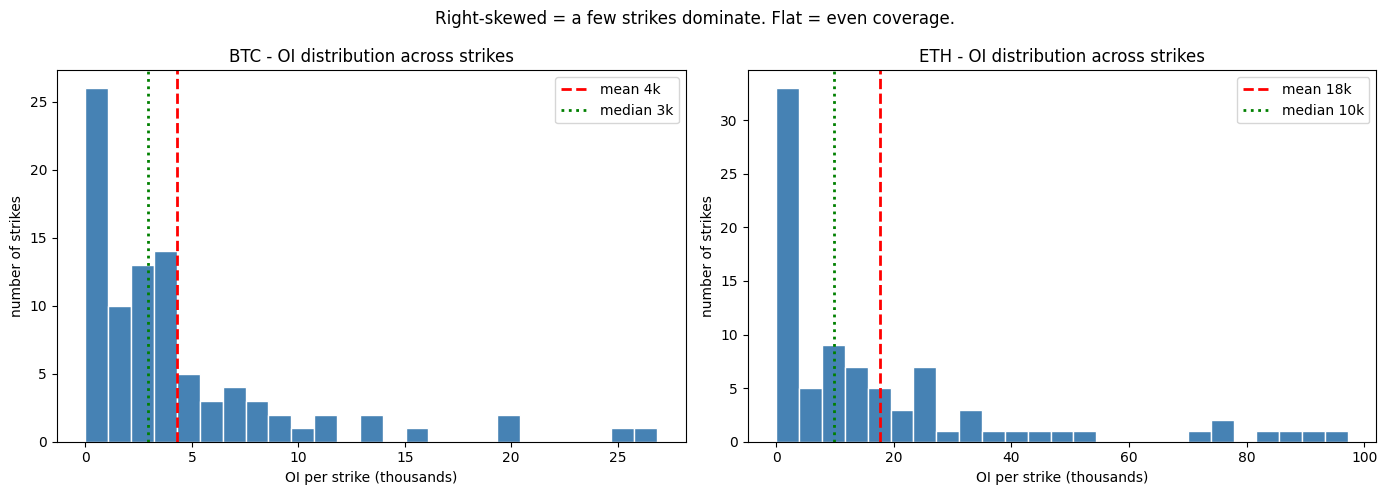

In [14]:
# Distribution of OI across strikes
# Skewed right = a few strikes dominate. Flat = even coverage.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur]
    oi_by_strike = s.groupby('strike').oi.sum().sort_values(ascending=False)
    if len(oi_by_strike) == 0: continue

    ax.hist(oi_by_strike.values / 1e3, bins=25, color='steelblue', edgecolor='white')
    ax.axvline(oi_by_strike.mean() / 1e3, color='red', lw=2, ls='--',
               label=f'mean {oi_by_strike.mean()/1e3:.0f}k')
    ax.axvline(oi_by_strike.median() / 1e3, color='green', lw=2, ls=':',
               label=f'median {oi_by_strike.median()/1e3:.0f}k')
    ax.set_title(f'{cur} - OI distribution across strikes')
    ax.set_xlabel('OI per strike (thousands)')
    ax.set_ylabel('number of strikes')
    ax.legend()

plt.suptitle('Right-skewed = a few strikes dominate. Flat = even coverage.', fontsize=12)
plt.tight_layout(); plt.show()

Volume vs OI ratio per strike (activity heat)


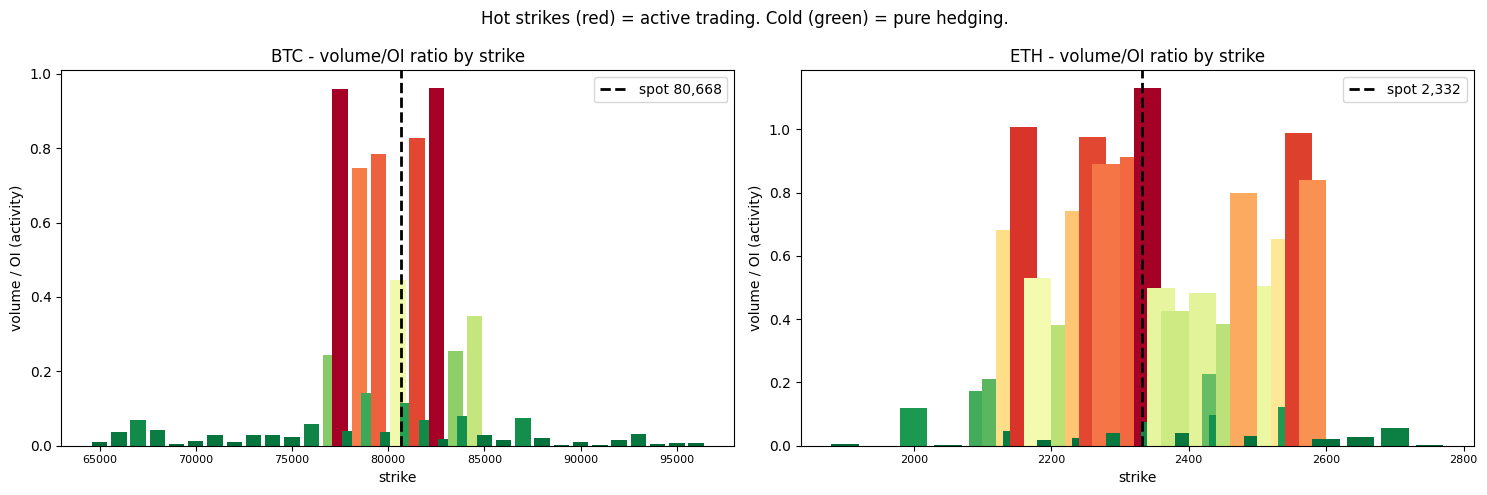


Interpretation:
  High volume/OI = someone is actively building or unwinding here
  Low volume/OI = static position, pure hedge
  Peak ratio near spot = market makers fighting at that strike


In [15]:
# Volume / OI ratio = how active is each strike?
# High ratio = lots of trading at that strike today = "hot" strike
# Low ratio = dormant strike = pure hedging

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur].copy()
    spot = spots[cur]
    s = s[(s.strike > spot * 0.8) & (s.strike < spot * 1.2)]
    s = s[(s.oi > 0) | (s.volume > 0)]

    if len(s) == 0: continue

    by_strike = s.groupby('strike').agg(
        oi=('oi', 'sum'),
        volume=('volume', 'sum'),
    )
    by_strike['ratio'] = by_strike.volume / by_strike.oi.replace(0, np.nan)
    by_strike = by_strike.dropna()

    if len(by_strike) == 0: continue

    x = by_strike.index
    colors = plt.cm.RdYlGn_r(by_strike.ratio / by_strike.ratio.max())

    ax.bar(x, by_strike.ratio, color=colors, width=(x[1]-x[0])*0.8 if len(x) > 1 else 100)
    ax.axvline(spot, color='black', lw=2, ls='--', label=f'spot {spot:,.0f}')
    ax.set_title(f'{cur} - volume/OI ratio by strike')
    ax.set_xlabel('strike')
    ax.set_ylabel('volume / OI (activity)')
    ax.legend()
    ax.tick_params(axis='x', labelsize=8)

plt.suptitle('Hot strikes (red) = active trading. Cold (green) = pure hedging.', fontsize=12)
plt.tight_layout(); plt.show()

print('\nInterpretation:')
print('  High volume/OI = someone is actively building or unwinding here')
print('  Low volume/OI = static position, pure hedge')
print('  Peak ratio near spot = market makers fighting at that strike')

Call/Put OI imbalance heatmap

C:\Users\Hp\AppData\Local\Temp\ipykernel_16296\1392433398.py:14: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivoted = s.pivot_table(index='strike', columns=['exp_bucket', 'kind'],


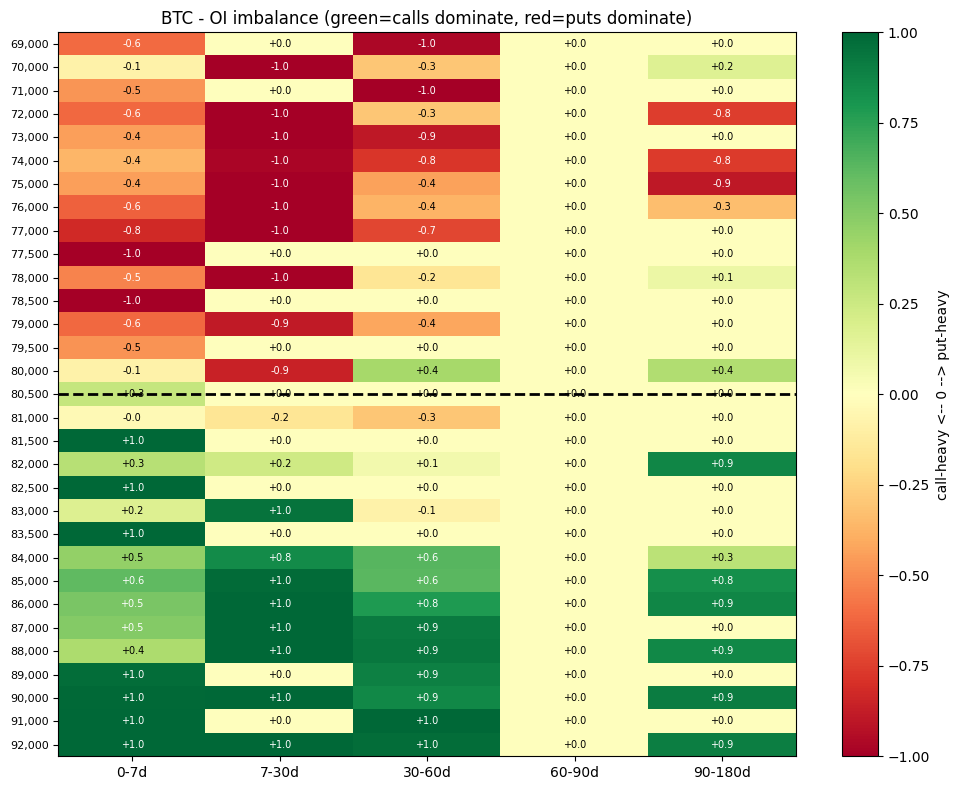

C:\Users\Hp\AppData\Local\Temp\ipykernel_16296\1392433398.py:14: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivoted = s.pivot_table(index='strike', columns=['exp_bucket', 'kind'],


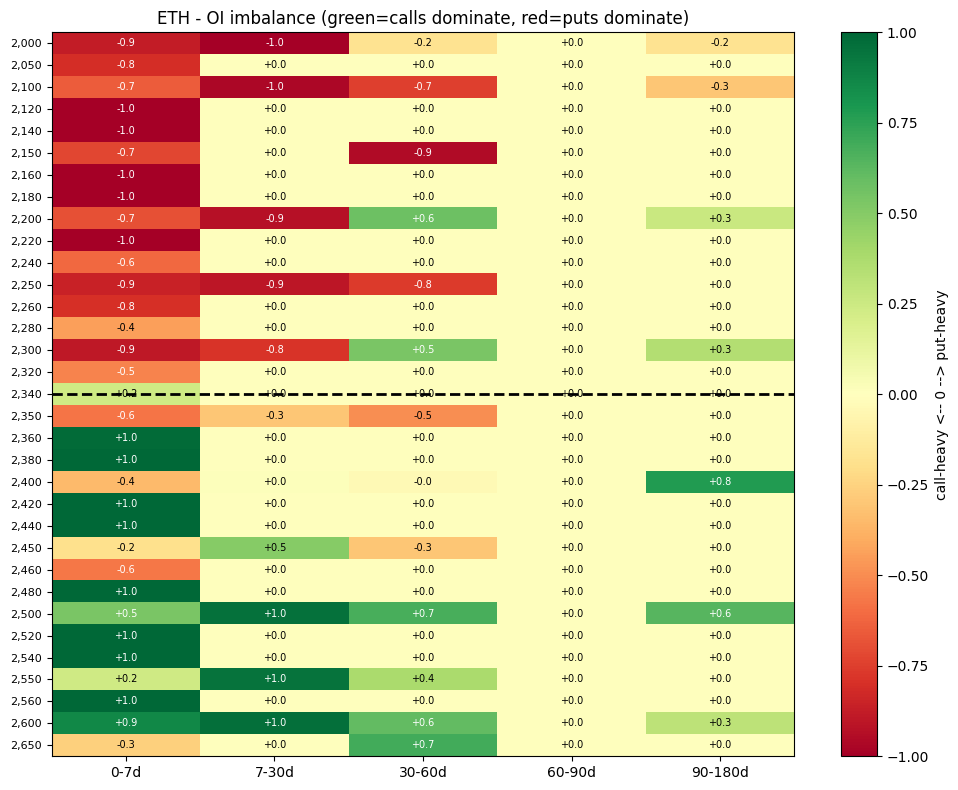

In [16]:
# For each (strike, expiry) combo, is call OI > put OI or vice versa?
# Green = call-heavy (bullish positioning). Red = put-heavy (bearish positioning).

for cur in COINS:
    s = df[(df.coin == cur) & (df.days.between(1, 180)) & ((df.oi > 0) | (df.volume > 0))].copy()
    spot = spots[cur]
    s = s[(s.strike > spot * 0.85) & (s.strike < spot * 1.15)]
    if len(s) == 0: continue

    s['exp_bucket'] = pd.cut(s.days,
                             bins=[0, 7, 30, 60, 90, 180],
                             labels=['0-7d', '7-30d', '30-60d', '60-90d', '90-180d'])

    pivoted = s.pivot_table(index='strike', columns=['exp_bucket', 'kind'],
                            values='oi', aggfunc='sum').fillna(0)

    # imbalance per (strike, expiry)
    imbalance = pd.DataFrame(index=pivoted.index)
    for exp in ['0-7d', '7-30d', '30-60d', '60-90d', '90-180d']:
        if (exp, 'C') in pivoted.columns and (exp, 'P') in pivoted.columns:
            c = pivoted[(exp, 'C')]
            p = pivoted[(exp, 'P')]
            imbalance[exp] = (c - p) / (c + p + 1e-9)  # -1 = all puts, +1 = all calls

    if len(imbalance) == 0: continue

    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(imbalance.values, cmap='RdYlGn', aspect='auto', vmin=-1, vmax=1)
    ax.set_xticks(range(len(imbalance.columns)))
    ax.set_xticklabels(imbalance.columns)
    ax.set_yticks(range(len(imbalance.index)))
    ax.set_yticklabels([f'{s:,.0f}' for s in imbalance.index], fontsize=8)
    ax.axhline(np.argmin(np.abs(imbalance.index - spot)), color='black', lw=2, ls='--')

    for i in range(imbalance.shape[0]):
        for j in range(imbalance.shape[1]):
            v = imbalance.iloc[i, j]
            if pd.notna(v):
                ax.text(j, i, f'{v:+.1f}',
                        ha='center', va='center', fontsize=7,
                        color='white' if abs(v) > 0.5 else 'black')

    plt.colorbar(im, ax=ax, label='call-heavy <-- 0 --> put-heavy')
    ax.set_title(f'{cur} - OI imbalance (green=calls dominate, red=puts dominate)')
    plt.tight_layout(); plt.show()

OI change proxy (top movers)


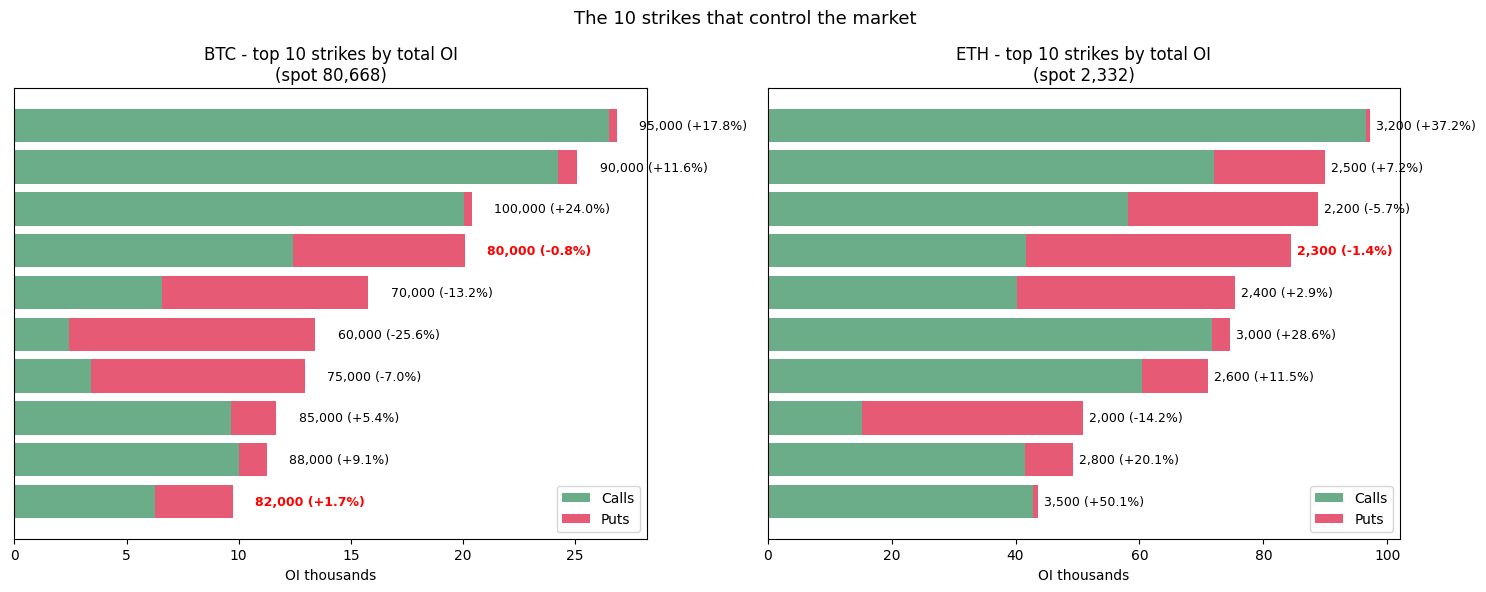

In [17]:
# Top 10 strikes by OI, with spot distance annotation
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur]
    spot = spots[cur]

    top = s.groupby('strike').agg(
        call_oi=('oi', lambda x: x[s.loc[x.index, 'kind']=='C'].sum()),
        put_oi=('oi', lambda x: x[s.loc[x.index, 'kind']=='P'].sum()),
    ) if False else None

    # simpler: pivot
    pvt = s.pivot_table(index='strike', columns='kind', values='oi', aggfunc='sum').fillna(0)
    pvt['total'] = pvt.sum(axis=1)
    top10 = pvt.nlargest(10, 'total').sort_values('total', ascending=True)

    if len(top10) == 0: continue

    y = np.arange(len(top10))
    ax.barh(y, top10.get('C', 0) / 1e3, color='seagreen', alpha=0.7, label='Calls')
    ax.barh(y, top10.get('P', 0) / 1e3, left=top10.get('C', 0) / 1e3,
            color='crimson', alpha=0.7, label='Puts')

    for i, strike in enumerate(top10.index):
        dist = (strike - spot) / spot * 100
        color = 'red' if abs(dist) < 2 else 'black'
        ax.text(top10.iloc[i]['total'] / 1e3 + 1, i,
                f'{strike:,.0f} ({dist:+.1f}%)',
                va='center', fontsize=9, color=color, fontweight='bold' if abs(dist) < 2 else 'normal')

    ax.axvline(0, color='black', lw=0.5)
    ax.set_yticks([])
    ax.set_title(f'{cur} - top 10 strikes by total OI\n(spot {spot:,.0f})')
    ax.set_xlabel('OI thousands')
    ax.legend(loc='lower right')

plt.suptitle('The 10 strikes that control the market', fontsize=13)
plt.tight_layout(); plt.show()

Term structure of call and put OI separately

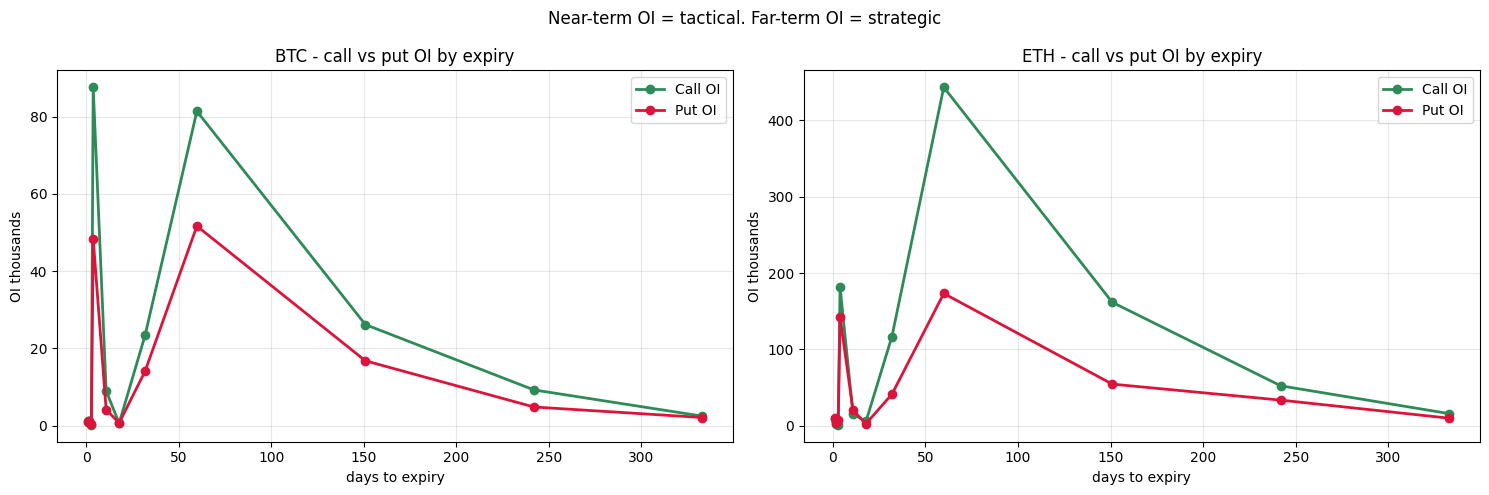

In [18]:
# Is call OI growing with expiry, and is put OI shrinking (or vice versa)?

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur].copy()
    s = s[(s.days > 0) & (s.days < 400)]
    if len(s) == 0: continue

    by_exp = s.groupby(['expiry', 'kind']).oi.sum().unstack('kind').fillna(0)
    by_exp['days'] = (by_exp.index - int(time.time() * 1000)) / 86_400_000
    by_exp = by_exp.sort_values('days')

    if 'C' in by_exp.columns:
        ax.plot(by_exp.days, by_exp['C'] / 1e3, marker='o', lw=2,
                color='seagreen', label='Call OI', ms=6)
    if 'P' in by_exp.columns:
        ax.plot(by_exp.days, by_exp['P'] / 1e3, marker='o', lw=2,
                color='crimson', label='Put OI', ms=6)

    ax.set_title(f'{cur} - call vs put OI by expiry')
    ax.set_xlabel('days to expiry')
    ax.set_ylabel('OI thousands')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Near-term OI = tactical. Far-term OI = strategic', fontsize=12)
plt.tight_layout(); plt.show()

Strike ladder with cumulative OI


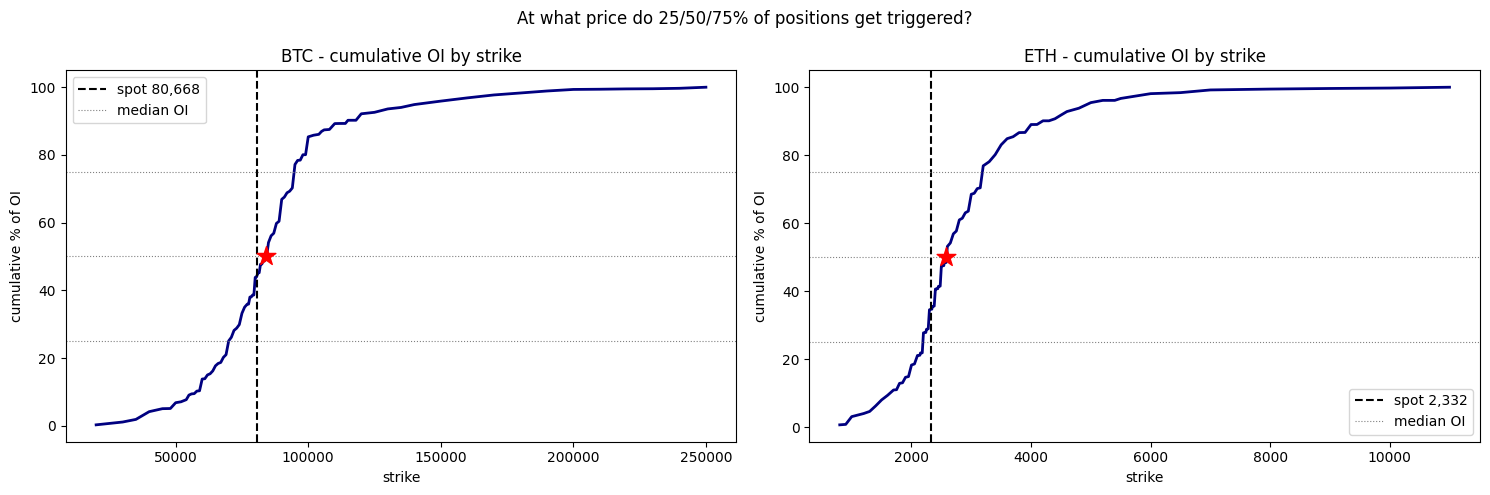

In [19]:
# Running sum of OI from bottom to top = cumulative defense
# Tells you: at what price does 25%, 50%, 75% of OI get triggered?

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur]
    spot = spots[cur]
    oi_by_strike = s.groupby('strike').oi.sum().sort_index()
    if len(oi_by_strike) == 0: continue

    cumsum = (oi_by_strike.cumsum() / oi_by_strike.sum()) * 100

    ax.plot(oi_by_strike.index, cumsum.values, lw=2, color='navy')
    ax.axvline(spot, color='black', ls='--', lw=1.5, label=f'spot {spot:,.0f}')
    ax.axhline(25, color='gray', ls=':', lw=0.8)
    ax.axhline(50, color='gray', ls=':', lw=0.8, label='median OI')
    ax.axhline(75, color='gray', ls=':', lw=0.8)

    # find strikes at percentiles
    idx_50 = np.argmin(np.abs(cumsum - 50))
    ax.scatter([oi_by_strike.index[idx_50]], [50], color='red', s=200,
               marker='*', zorder=5)

    ax.set_title(f'{cur} - cumulative OI by strike')
    ax.set_xlabel('strike')
    ax.set_ylabel('cumulative % of OI')
    ax.legend()

plt.suptitle('At what price do 25/50/75% of positions get triggered?', fontsize=12)
plt.tight_layout(); plt.show()

OI concentration bar (sorted strikes)

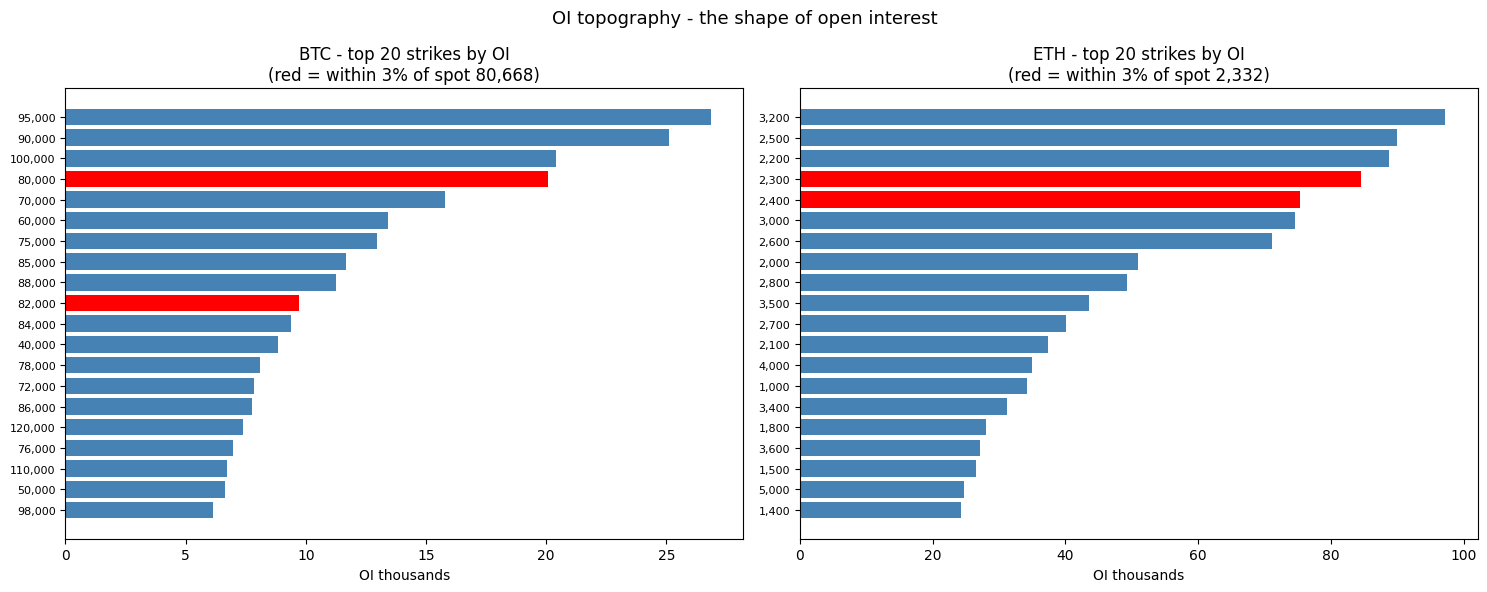

In [20]:
# Sorted OI bar chart per coin - see the "topography" of open interest
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur]
    spot = spots[cur]
    oi_by_strike = s.groupby('strike').oi.sum().sort_values(ascending=False)
    if len(oi_by_strike) == 0: continue

    top20 = oi_by_strike.head(20).sort_values(ascending=True)
    colors = ['red' if abs(strike - spot) / spot < 0.03 else 'steelblue'
              for strike in top20.index]

    ax.barh(range(len(top20)), top20.values / 1e3, color=colors)
    ax.set_yticks(range(len(top20)))
    ax.set_yticklabels([f'{int(s):,}' for s in top20.index], fontsize=8)
    ax.set_xlabel('OI thousands')
    ax.set_title(f'{cur} - top 20 strikes by OI\n(red = within 3% of spot {spot:,.0f})')

plt.suptitle('OI topography - the shape of open interest', fontsize=13)
plt.tight_layout(); plt.show()

Full OI summary dashboard


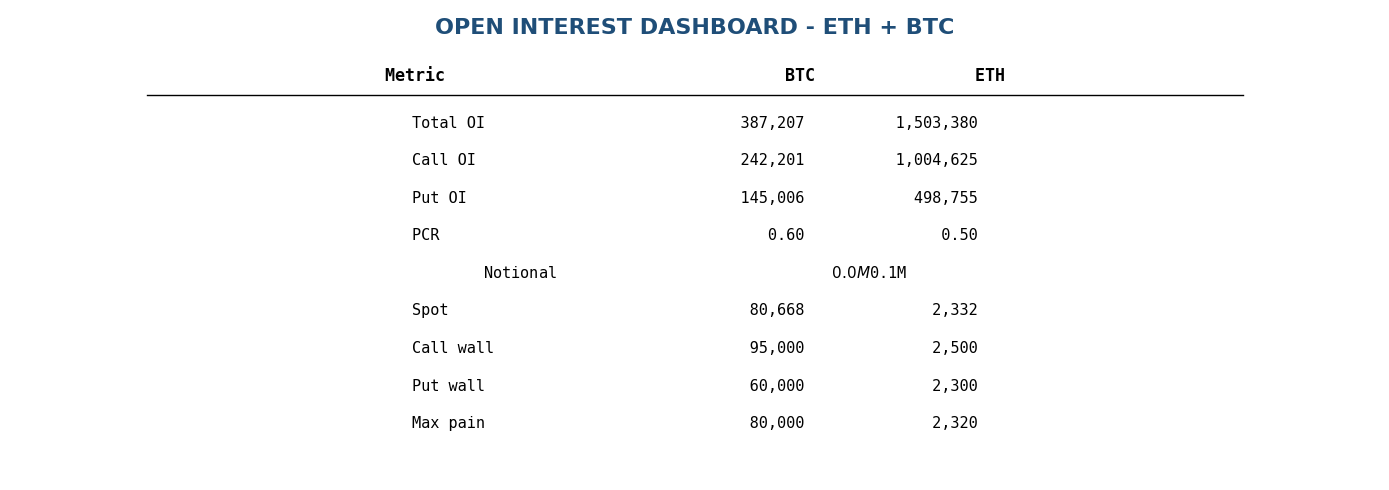

In [21]:
# One-page dashboard - all OI stats per coin
fig, ax = plt.subplots(figsize=(14, 5))
ax.axis('off')

ax.text(0.5, 0.95, 'OPEN INTEREST DASHBOARD - ETH + BTC',
        ha='center', fontsize=16, fontweight='bold',
        transform=ax.transAxes, color='#1F4E78')

header = f"{'Metric':<24} {'BTC':>18} {'ETH':>18}"
ax.text(0.5, 0.85, header, ha='center', family='monospace',
        fontsize=12, fontweight='bold', transform=ax.transAxes)
ax.plot([0.1, 0.9], [0.82, 0.82], color='black', lw=1, transform=ax.transAxes)

metrics = []
for cur in COINS:
    s = df[df.coin == cur]
    spot = spots[cur]
    call_oi = s[s.kind=='C'].oi.sum()
    put_oi = s[s.kind=='P'].oi.sum()
    total = call_oi + put_oi
    notional = (s.mark.fillna(0) * s.oi).sum()

    w = walls.get(cur, {})
    mp = mp_data.get(cur, spot) if 'mp_data' in dir() else spot

    metrics.append({
        'Total OI': f'{total:,.0f}',
        'Call OI': f'{call_oi:,.0f}',
        'Put OI': f'{put_oi:,.0f}',
        'PCR': f'{put_oi/max(call_oi,1):.2f}',
        'Notional': f'${notional/1e6:.1f}M',
        'Spot': f'{spot:,.0f}',
        'Call wall': f"{w.get('call', 0):,.0f}",
        'Put wall': f"{w.get('put', 0):,.0f}",
        'Max pain': f'{mp:,.0f}',
    })

metric_names = list(metrics[0].keys())
y = 0.75
for name in metric_names:
    line = f'{name:<24} {metrics[0][name]:>18} {metrics[1][name]:>18}'
    ax.text(0.5, y, line, ha='center', family='monospace', fontsize=11,
            transform=ax.transAxes)
    y -= 0.08

plt.tight_layout(); plt.show()

OI change vs IV change (positioning pressure

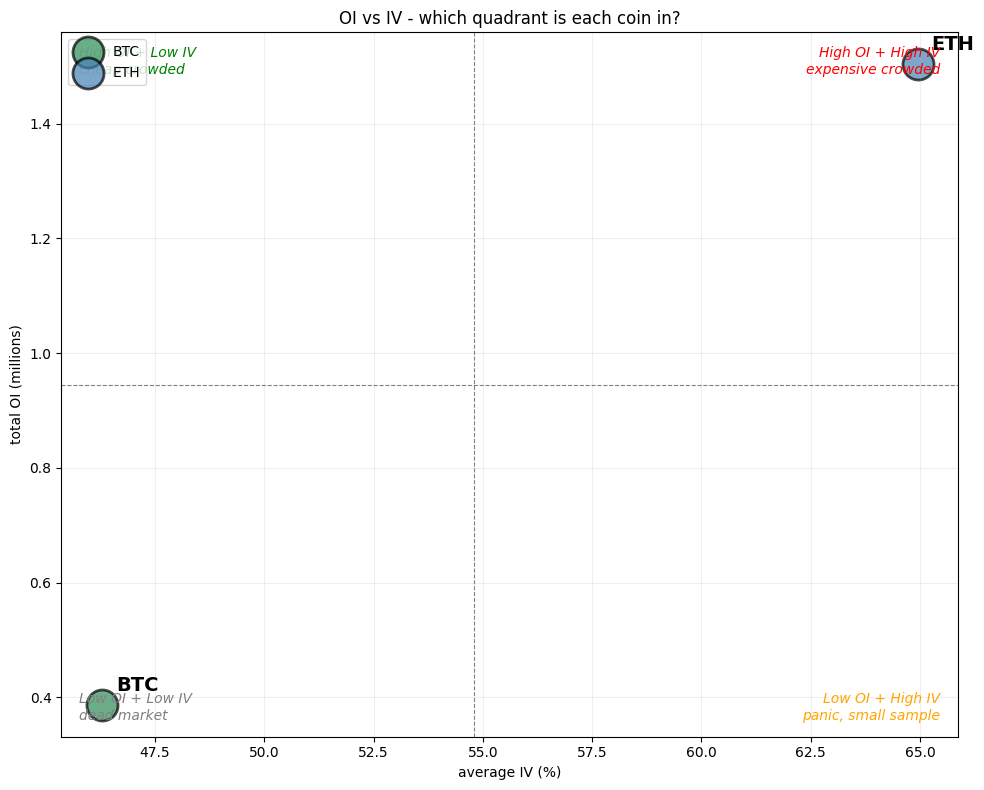

In [22]:
# High OI + high IV = expensive crowded trade
# High OI + low IV = cheap crowded trade (buyer's opportunity)
# Low OI + high IV = panic, few positions (small sample)
# Low OI + low IV = dead market

fig, ax = plt.subplots(figsize=(10, 8))

for cur in COINS:
    s = df[(df.coin == cur) & df.iv_dec.notna()]
    if len(s) == 0: continue

    total_oi = s.oi.sum()
    avg_iv = s.iv_dec.mean() * 100

    color = 'seagreen' if cur == 'BTC' else 'steelblue'
    ax.scatter(avg_iv, total_oi / 1e6, s=500, color=color, alpha=0.7,
               edgecolor='black', linewidth=2, label=cur)
    ax.annotate(cur, (avg_iv, total_oi / 1e6),
                textcoords='offset points', xytext=(10, 10),
                fontsize=14, fontweight='bold')

# quadrants
ax.axvline(df.iv_dec.mean() * 100, color='gray', ls='--', lw=0.8)
ax.axhline(df.oi.sum() / len(COINS) / 1e6, color='gray', ls='--', lw=0.8)

ax.text(0.02, 0.98, 'High OI + Low IV\ncheap crowded',
        transform=ax.transAxes, fontsize=10, va='top', style='italic', color='green')
ax.text(0.98, 0.98, 'High OI + High IV\nexpensive crowded',
        transform=ax.transAxes, fontsize=10, va='top', ha='right', style='italic', color='red')
ax.text(0.02, 0.02, 'Low OI + Low IV\ndead market',
        transform=ax.transAxes, fontsize=10, va='bottom', style='italic', color='gray')
ax.text(0.98, 0.02, 'Low OI + High IV\npanic, small sample',
        transform=ax.transAxes, fontsize=10, va='bottom', ha='right', style='italic', color='orange')

ax.set_xlabel('average IV (%)')
ax.set_ylabel('total OI (millions)')
ax.set_title('OI vs IV - which quadrant is each coin in?')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

Strike-by-strike OI side-by-side

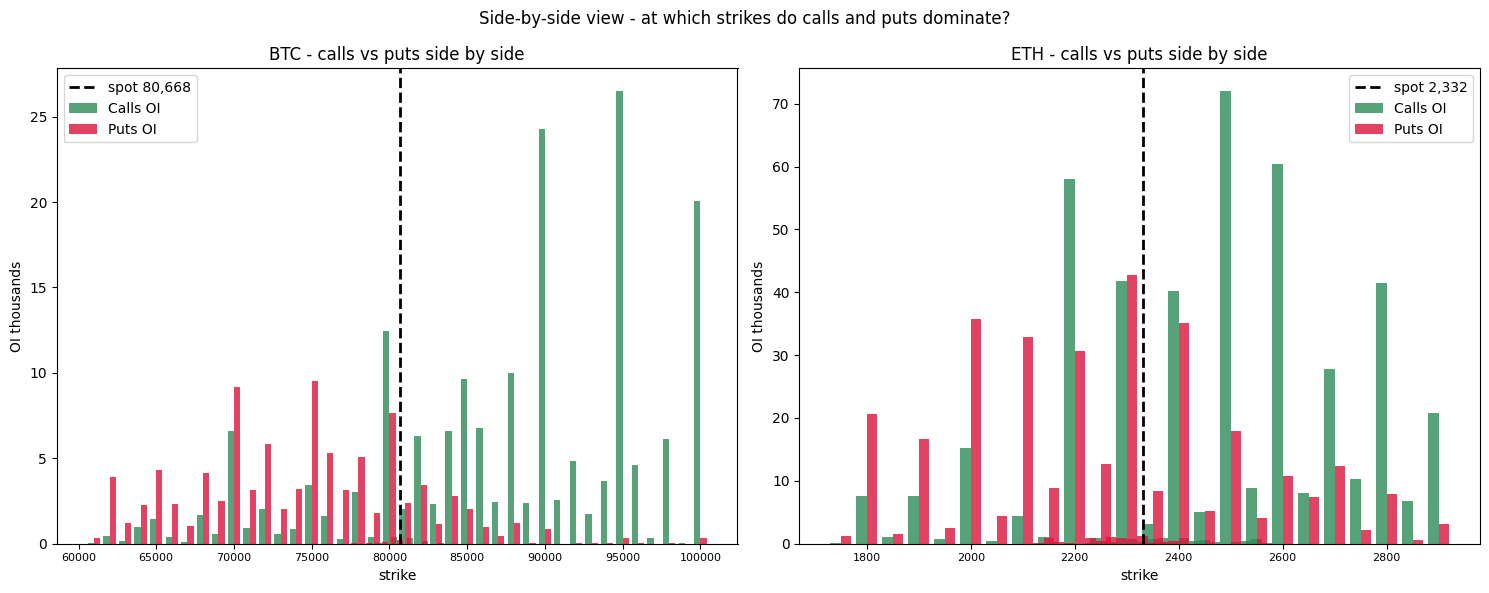

In [23]:
# Calls and puts side by side per strike - mirror view
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur]
    spot = spots[cur]
    s_near = s[(s.strike > spot * 0.75) & (s.strike < spot * 1.25)]
    pivot = s_near.pivot_table(index='strike', columns='kind',
                                values='oi', aggfunc='sum').fillna(0)

    if len(pivot) == 0: continue

    x = pivot.index
    w = (x[1] - x[0]) * 0.4 if len(x) > 1 else 50

    ax.bar(x - w/2, pivot.get('C', 0) / 1e3, w, color='seagreen',
           label='Calls OI', alpha=0.8)
    ax.bar(x + w/2, pivot.get('P', 0) / 1e3, w, color='crimson',
           label='Puts OI', alpha=0.8)
    ax.axvline(spot, color='black', lw=2, ls='--', label=f'spot {spot:,.0f}')
    ax.set_title(f'{cur} - calls vs puts side by side')
    ax.set_xlabel('strike'); ax.set_ylabel('OI thousands')
    ax.legend()
    ax.tick_params(axis='x', labelsize=8)

plt.suptitle('Side-by-side view - at which strikes do calls and puts dominate?', fontsize=12)
plt.tight_layout(); plt.show()

Total OI by expiry AND kind (grouped bars)

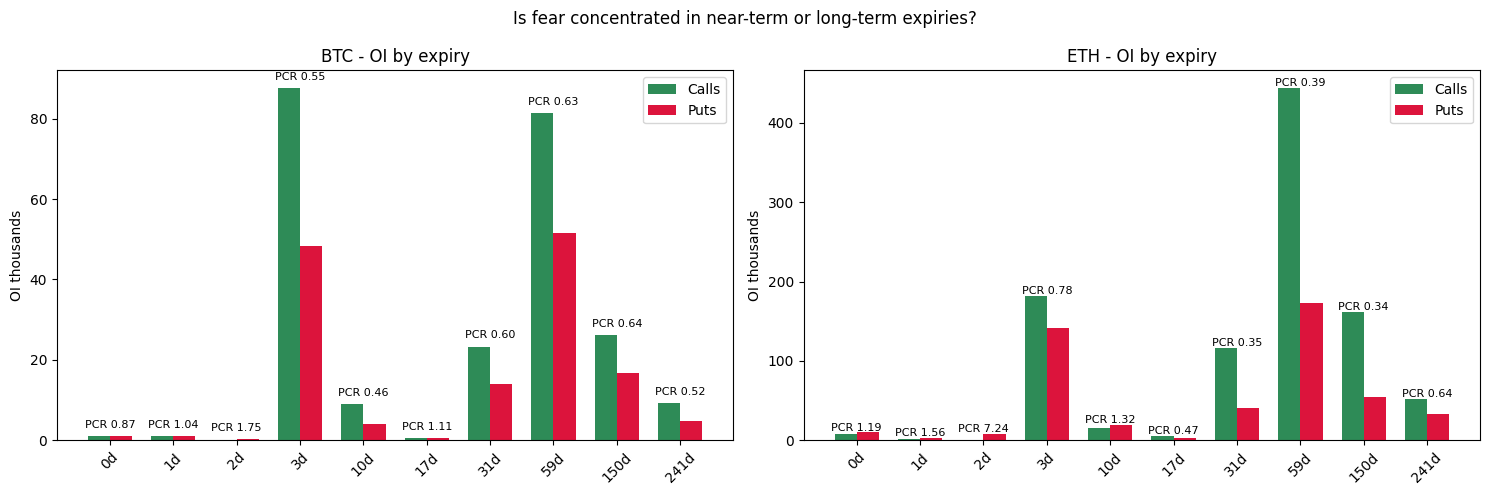

In [24]:
# Grouped bar chart: OI per expiry, split by call/put
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    s = df[df.coin == cur].copy()
    s = s[(s.days > 0) & (s.days < 250)]
    if len(s) == 0: continue

    by_exp = s.groupby(['expiry', 'kind']).oi.sum().unstack('kind').fillna(0)
    by_exp['days'] = (by_exp.index - int(time.time() * 1000)) / 86_400_000
    by_exp = by_exp.sort_values('days').head(10)

    x = np.arange(len(by_exp))
    w = 0.35
    bars_c = ax.bar(x - w/2, by_exp.get('C', 0) / 1e3, w, color='seagreen', label='Calls')
    bars_p = ax.bar(x + w/2, by_exp.get('P', 0) / 1e3, w, color='crimson', label='Puts')

    ax.set_xticks(x)
    ax.set_xticklabels([f'{int(d)}d' for d in by_exp.days], rotation=45)
    ax.set_title(f'{cur} - OI by expiry')
    ax.set_ylabel('OI thousands')
    ax.legend()

    # add PCR label per expiry
    for i, (c, p) in enumerate(zip(by_exp.get('C', 0), by_exp.get('P', 0))):
        pcr_val = p / max(c, 1)
        ax.text(i, max(c, p) / 1e3 + 2, f'PCR {pcr_val:.2f}',
                ha='center', fontsize=8, color='black')

plt.suptitle('Is fear concentrated in near-term or long-term expiries?', fontsize=12)
plt.tight_layout(); plt.show()